# Exploratory Analysis of Quantum Dot Blinking

## Dataset
qdb_20260824_102327.raw

## Aim
Explore the spatial and temporal fluorescence characteristics
of detected quantum dot candidates.

Initially, compare differences in brightness, fitted width,
and fluorescence variability.

## Research context
This analysis builds on the methods in
*A practical guide for wide-field imaging of quantum dot blinking*.

The aim is to investigate which measurements might eventually
help distinguish isolated emitters from unresolved clusters.

Candidate detection does not establish the number of quantum dots.

In [16]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find results from the selected experimental recording
results_root = Path("qd_blinking_results")

folders = sorted(
    results_root.glob("qdb_20260824_102327_raw_*"),
    key=lambda p: p.stat().st_mtime
)

if not folders:
    raise FileNotFoundError("No experimental analysis results found.")

folder = folders[-1]

# Load previously exported results
candidates = pd.read_csv(folder / "retained_candidates.csv")
statistics = pd.read_csv(folder / "trace_statistics.csv")
traces = pd.read_csv(folder / "extracted_traces.csv")

print("Dataset:", folder.name)
print("Retained candidates:", len(candidates))
print("Extracted traces:", traces["candidate_id"].nunique())
print("Total measurements:", len(traces))

Dataset: qdb_20260824_102327_raw_20261020T145929_676324Z
Retained candidates: 168
Extracted traces: 168
Total measurements: 168000


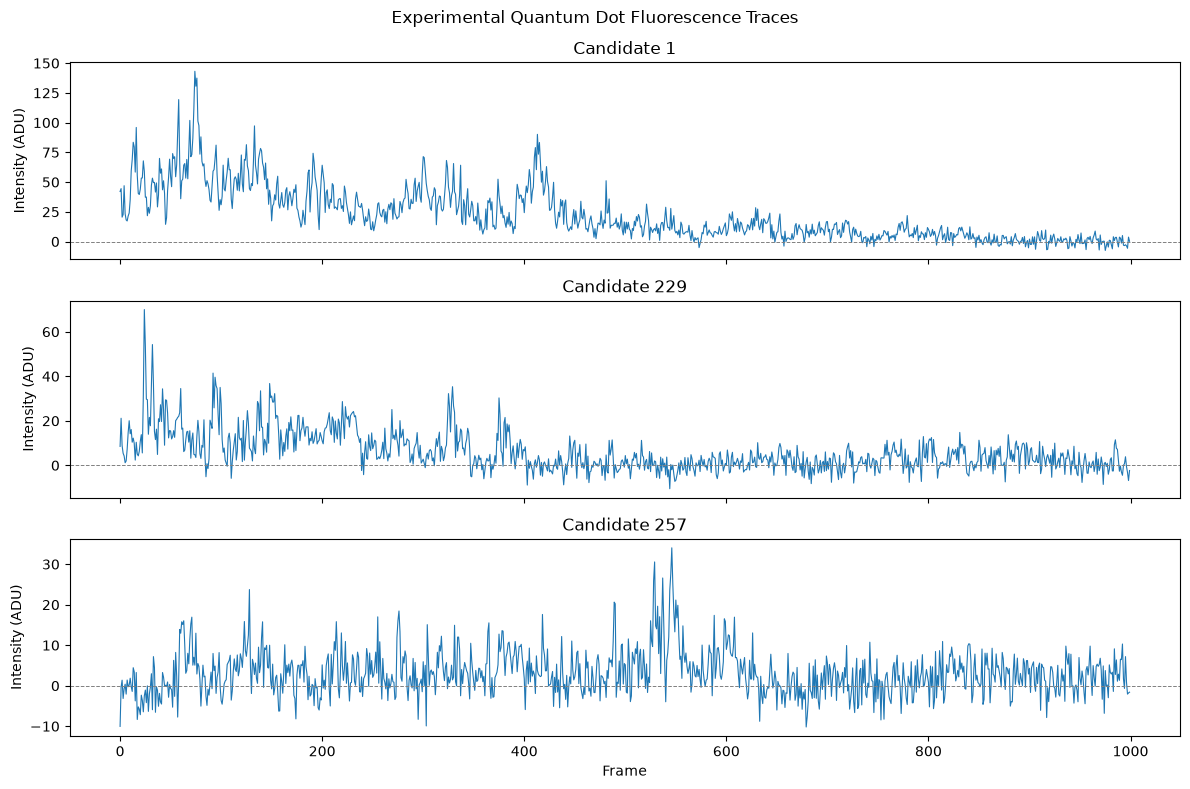

In [17]:
candidate_ids = [1, 229, 257]

fig, axes = plt.subplots(
    len(candidate_ids), 1,
    figsize=(12, 8),
    sharex=True
)

for ax, cid in zip(axes, candidate_ids):
    trace = traces[traces["candidate_id"] == cid]

    if trace["time_s"].notna().all():
        x = trace["time_s"]
        xlabel = "Time (s)"
    else:
        x = trace["frame"]
        xlabel = "Frame"

    ax.plot(
        x,
        trace["corrected_mean_counts"],
        linewidth=0.8
    )

    ax.axhline(0, linestyle="--", color="gray", linewidth=0.7)
    ax.set_ylabel("Intensity (ADU)")
    ax.set_title(f"Candidate {cid}")

axes[-1].set_xlabel(xlabel)

fig.suptitle("Experimental Quantum Dot Fluorescence Traces")
plt.tight_layout()
plt.show()

## Temporal changes in fluorescence intensity

The experimental traces exhibit substantial changes in
fluorescence intensity over time.

To investigate these changes, the mean corrected intensity
during the first and last 200 frames is compared.

This provides a descriptive measurement of temporal
brightness changes but does not independently establish
photobleaching or any particular blinking mechanism.

In [18]:
# Compare the beginning and end of each fluorescence trace

results = []

for cid, group in traces.groupby("candidate_id"):

    group = group.sort_values("frame")
    intensity = group["corrected_mean_counts"].to_numpy()

    early_mean = intensity[:200].mean()
    late_mean = intensity[-200:].mean()

    results.append({
        "candidate_id": cid,
        "early_mean": early_mean,
        "late_mean": late_mean,
        "intensity_change": late_mean - early_mean
    })

temporal_summary = pd.DataFrame(results)

display(
    temporal_summary[
        temporal_summary["candidate_id"].isin([1, 229, 257])
    ].round(2)
)

,candidate_id,early_mean,late_mean,intensity_change
0,1,51.24,1.80,-49.44
147,229,15.34,2.57,-12.78
163,257,2.32,2.51,0.18


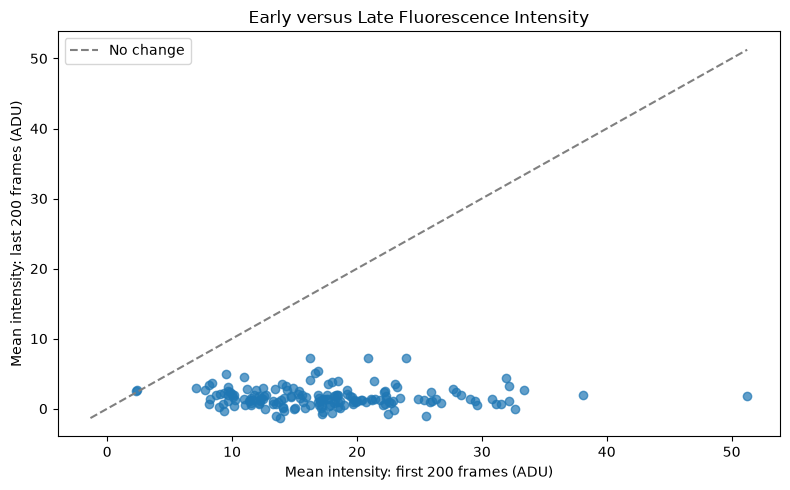

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    temporal_summary["early_mean"],
    temporal_summary["late_mean"],
    alpha=0.7
)

low = min(
    temporal_summary["early_mean"].min(),
    temporal_summary["late_mean"].min()
)

high = max(
    temporal_summary["early_mean"].max(),
    temporal_summary["late_mean"].max()
)

ax.plot([low, high], [low, high],
        linestyle="--", color="gray",
        label="No change")

ax.set_xlabel("Mean intensity: first 200 frames (ADU)")
ax.set_ylabel("Mean intensity: last 200 frames (ADU)")
ax.set_title("Early versus Late Fluorescence Intensity")
ax.legend()

plt.tight_layout()
plt.show()

## Population-wide fluorescence evolution

The early-versus-late comparison suggests that many detected
fluorescent features become dimmer during the recording.

To investigate whether this behaviour is shared across the
candidate population, the mean and median background-corrected
intensity are calculated for every frame.

These statistics describe the detected candidate population.
They do not establish the physical cause of fluorescence loss.

Potential explanations include photobleaching, photodarkening,
long-lived dark states and changes in experimental conditions.

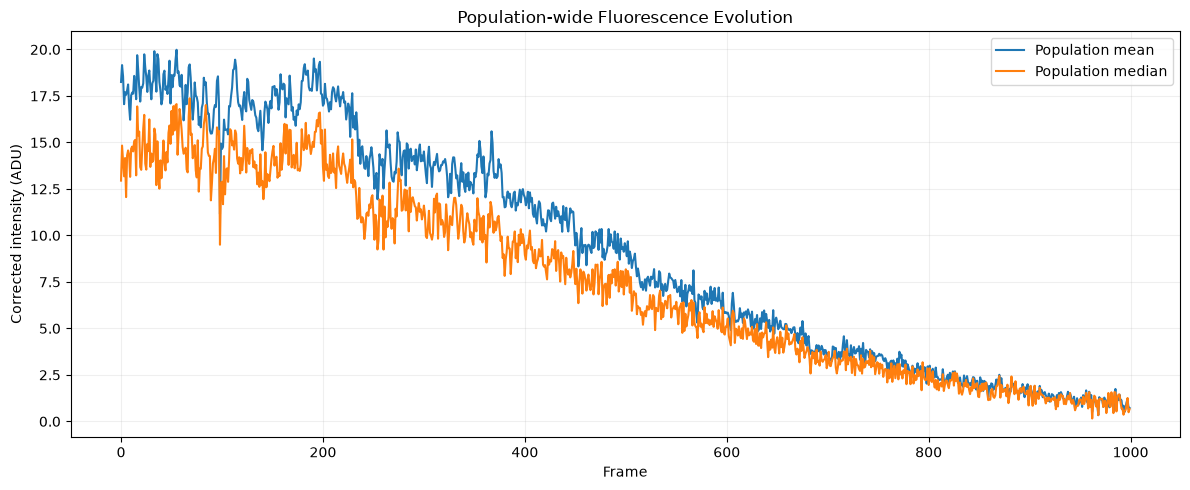

In [20]:
# Calculate population-wide fluorescence statistics

population = (
    traces.groupby("frame")["corrected_mean_counts"]
    .agg(["mean", "median", "std"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    population["frame"],
    population["mean"],
    label="Population mean",
    linewidth=1.5
)

ax.plot(
    population["frame"],
    population["median"],
    label="Population median",
    linewidth=1.5
)

ax.set_xlabel("Frame")
ax.set_ylabel("Corrected intensity (ADU)")
ax.set_title("Population-wide Fluorescence Evolution")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Population-Wide Fluorescence Evolution

The graph shows the mean and median background-corrected fluorescence intensity across all 168 retained candidates over the 1,000-frame recording.

Both the population mean (blue) and median (orange) show a substantial decrease in fluorescence intensity over time, falling from approximately 18 and 14 ADU respectively to around 1 ADU by the end of the recording. Although short-term fluctuations are present, the overall trend is a progressive reduction in fluorescence across the candidate population.

The mean remains consistently above the median, particularly during the early frames, suggesting that a subset of brighter candidates contributes disproportionately to the average intensity.

This behaviour could be consistent with **photobleaching or photodarkening**, where quantum dots lose fluorescence under sustained illumination. However, changes in experimental conditions, such as excitation intensity or focus drift, could also contribute. Further investigation would be required to determine the physical cause.

### Summary of Exploratory Analysis So Far

- Successfully reproduced the original analysis pipeline on the experimental recording `qdb_20260824_102327.raw`.
- Detected **264 fluorescent features**, of which **168 passed the Gaussian-fitting and quality-selection criteria**.
- Extracted 1,000-frame background-corrected intensity traces for all 168 retained candidates.
- Examined individual candidates, identifying considerable differences in brightness, intensity fluctuations and temporal behaviour.
- Compared the first and last 200 frames, finding that most candidates exhibited a substantial reduction in fluorescence intensity.
- Confirmed through population-wide analysis that fluorescence generally decreases throughout the recording.

### Initial Conclusions

The experimental traces exhibit considerably more complex behaviour than the synthetic demonstration data. In particular, the widespread decline in fluorescence suggests that time-dependent intensity changes may need to be accounted for when developing automated blinking analysis methods.

These observations provide an initial understanding of the dataset and highlight important considerations for future work, particularly the challenge of distinguishing individual quantum dots from unresolved clusters using their fluorescence behaviour.

## Spatial Excitation Profile Analysis

### Aim

The aim of this analysis is to investigate the spatial variation in fluorescence intensity across the field of view and determine whether it could provide an approximate indication of the nonuniform excitation intensity experienced by individual quantum dots (QDs).

The excitation laser was deliberately defocused to illuminate a larger region of the sample. Consequently, QDs at different positions may experience different local excitation intensities despite the nominal laser power remaining constant.

### Method

A time-averaged image is calculated from the experimental video to visualise the overall spatial intensity distribution. A spatial median filter followed by Gaussian smoothing is used to suppress localised bright features and estimate the broad background intensity profile.

The resulting image is examined alongside a horizontal intensity cross-section to characterise the variation across the field of view.

### Limitations

The measured image intensity represents camera-recorded light rather than a direct measurement of excitation irradiance. Spatial variations may also arise from QD concentration, out-of-focus fluorescence, optical scattering and detection nonuniformity.

The current analysis uses an 8-bit cropped MP4 rather than the original 16-bit RAW acquisition. Consequently, intensities are interpreted as relative video grey levels rather than calibrated camera counts or optical power.

This analysis is therefore exploratory. The spatial profile may eventually be used as a relative excitation-intensity proxy, but this assumption must be assessed before drawing conclusions about excitation-dependent QD blinking.

In [22]:

from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import median_filter, gaussian_filter
from skimage.feature import peak_local_max

# Select experimental video
VIDEO_PATH = Path(
    "/Users/william/Documents/UNI/MASTERS PROJECT/WT_MastersRepo/qd_blinking_supplementary_code/Exp_Data/102327_cropped.mp4"
)

if not VIDEO_PATH.is_file():
    raise FileNotFoundError(
        f"Video not found: {VIDEO_PATH.resolve()}\n"
        "Place the video beside the notebook or update VIDEO_PATH."
    )

# Adjustable exploratory parameters
FRAME_STEP = 5
MEDIAN_SIZE = 41
SMOOTHING_SIGMA = 20

print(f"Selected video: {VIDEO_PATH.name}")


Selected video: 102327_cropped.mp4


Video dimensions: (500, 500)
Frames used: 200
Frame rate: 20.00 fps


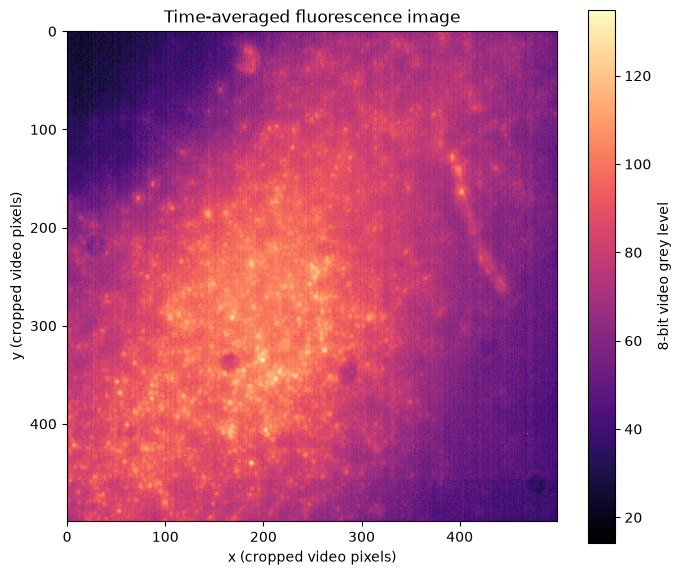

In [23]:

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError("Could not open the selected video.")

frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)

sum_image = None
frames_used = 0

try:
    for frame_index in range(frame_count):
        success, frame = cap.read()

        if not success:
            break

        if frame_index % FRAME_STEP != 0:
            continue

        gray = cv2.cvtColor(
            frame, cv2.COLOR_BGR2GRAY
        ).astype(np.float64)

        if sum_image is None:
            sum_image = np.zeros_like(gray)

        sum_image += gray
        frames_used += 1
finally:
    cap.release()

if frames_used == 0:
    raise RuntimeError("No video frames could be read.")

mean_image = sum_image / frames_used

print(f"Video dimensions: {mean_image.shape}")
print(f"Frames used: {frames_used}")
print(f"Frame rate: {fps:.2f} fps")

plt.figure(figsize=(7, 6))

plt.imshow(mean_image, cmap="magma", origin="upper")
plt.colorbar(label="8-bit video grey level")

plt.title("Time-averaged fluorescence image")
plt.xlabel("x (cropped video pixels)")
plt.ylabel("y (cropped video pixels)")

plt.tight_layout()
plt.show()


### Estimating the Broad Spatial Background

The time-averaged image contains both localised fluorescent features and a broad spatial intensity distribution.

To investigate the broad distribution separately, a median filter is applied to reduce the influence of small bright and dark features. Gaussian smoothing is subsequently applied to estimate the slowly varying background.

The resulting profile is intended to represent the broad spatial variation in recorded image brightness. It does not directly measure excitation irradiance.

The filtering parameters are initially selected for exploratory visual analysis and will need to be assessed for sensitivity and possible distortion of the underlying spatial profile.

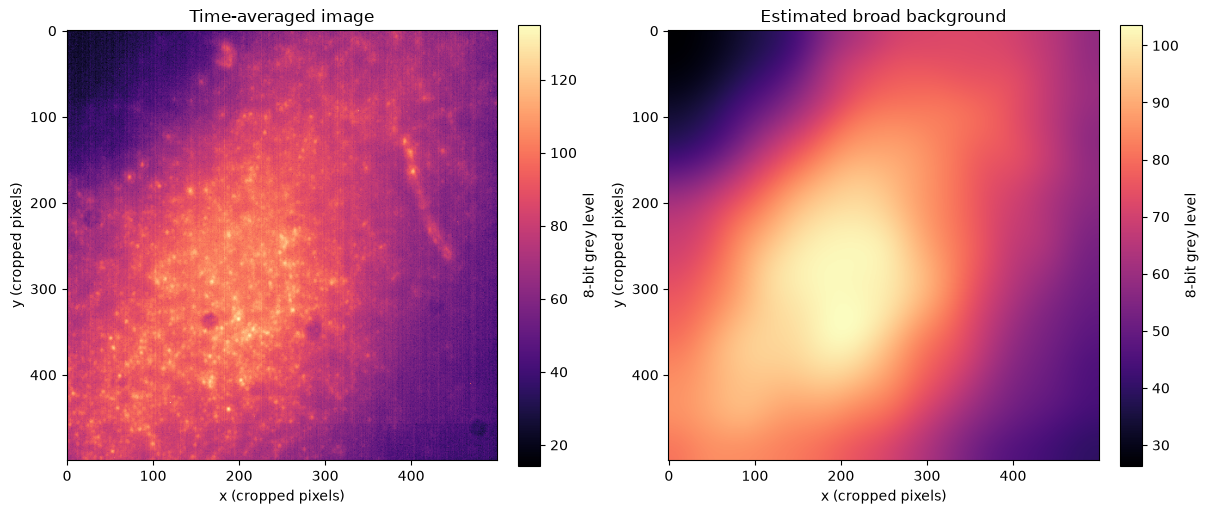

Estimated background range: 26.34 to 103.59


In [26]:

# Suppress localised features using a spatial median filter
median_image = median_filter(
    mean_image,
    size=MEDIAN_SIZE,
    mode="reflect"
)

# Smooth the remaining broad spatial structure
background_image = gaussian_filter(
    median_image,
    sigma=SMOOTHING_SIGMA
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    constrained_layout=True
)

im0 = axes[0].imshow(
    mean_image,
    cmap="magma",
    origin="upper"
)
axes[0].set_title("Time-averaged image")

im1 = axes[1].imshow(
    background_image,
    cmap="magma",
    origin="upper"
)
axes[1].set_title("Estimated broad background")

for ax in axes:
    ax.set_xlabel("x (cropped pixels)")
    ax.set_ylabel("y (cropped pixels)")

fig.colorbar(
    im0, ax=axes[0],
    label="8-bit grey level"
)

fig.colorbar(
    im1, ax=axes[1],
    label="8-bit grey level"
)

plt.show()

print(
    "Estimated background range:",
    f"{background_image.min():.2f} to "
    f"{background_image.max():.2f}"
)


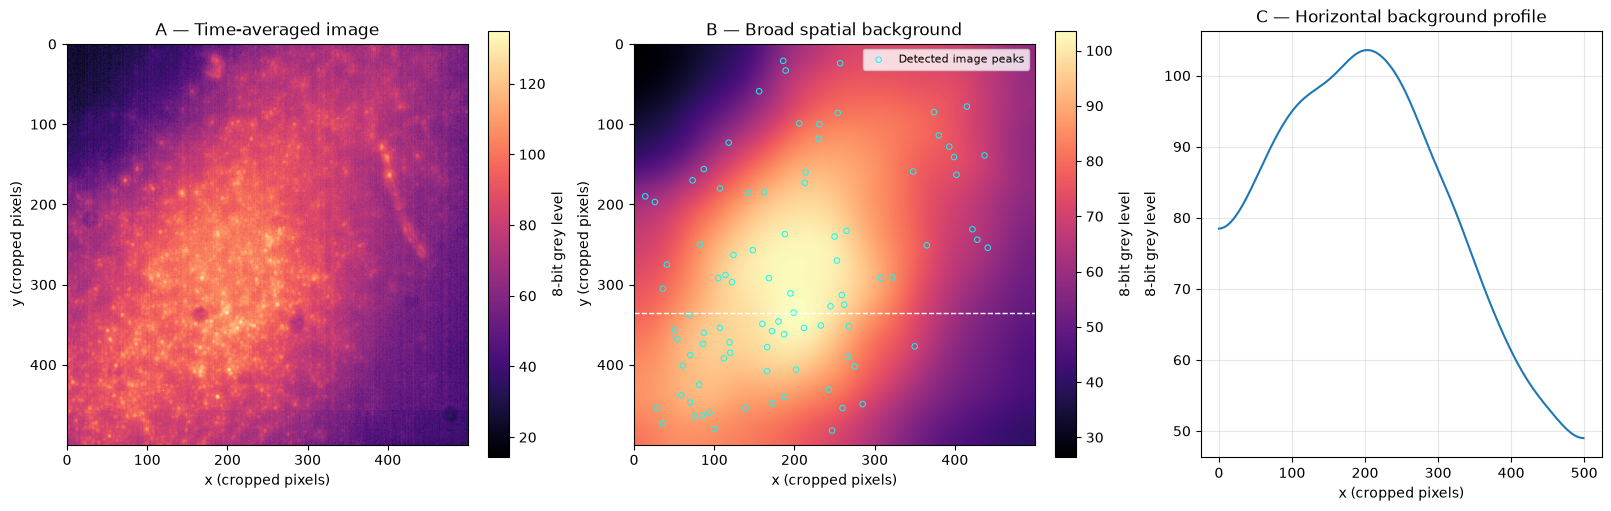

Detected image peaks displayed: 90
Broad background maximum at: (203, 335)


In [25]:

# Detect local positive features above the estimated background
contrast_image = gaussian_filter(
    mean_image - background_image,
    sigma=1.2
)

peaks = peak_local_max(
    contrast_image,
    min_distance=7,
    threshold_abs=8,
    exclude_border=12
)

# Show up to 90 strongest peaks for visual clarity
peaks = sorted(
    peaks,
    key=lambda p: contrast_image[tuple(p)],
    reverse=True
)[:90]

peaks = np.asarray(peaks, dtype=int).reshape(-1, 2)

# Locate the maximum of the broad background
y_peak, x_peak = np.unravel_index(
    np.argmax(background_image),
    background_image.shape
)

# Horizontal cross-section through that maximum
horizontal_profile = background_image[y_peak, :]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    constrained_layout=True
)

# Panel A
im0 = axes[0].imshow(mean_image, cmap="magma")
axes[0].set_title("A — Time-averaged image")

fig.colorbar(
    im0, ax=axes[0],
    label="8-bit grey level"
)

# Panel B
im1 = axes[1].imshow(background_image, cmap="magma")
axes[1].set_title("B — Broad spatial background")

if len(peaks) > 0:
    axes[1].scatter(
        peaks[:, 1],
        peaks[:, 0],
        s=16,
        facecolors="none",
        edgecolors="cyan",
        linewidths=0.7,
        label="Detected image peaks"
    )
    axes[1].legend(fontsize=8)

axes[1].axhline(
    y_peak,
    color="white",
    linestyle="--",
    linewidth=1
)

fig.colorbar(
    im1, ax=axes[1],
    label="8-bit grey level"
)

# Panel C
axes[2].plot(
    np.arange(background_image.shape[1]),
    horizontal_profile
)

axes[2].set_title("C — Horizontal background profile")
axes[2].set_xlabel("x (cropped pixels)")
axes[2].set_ylabel("8-bit grey level")
axes[2].grid(alpha=0.3)

for ax in axes[:2]:
    ax.set_xlabel("x (cropped pixels)")
    ax.set_ylabel("y (cropped pixels)")

plt.show()

print(f"Detected image peaks displayed: {len(peaks)}")
print(f"Broad background maximum at: ({x_peak}, {y_peak})")


### Initial Interpretation and Next Steps

The time-averaged image shows a nonuniform spatial intensity distribution, with a broad region of increased brightness surrounded by areas of lower recorded intensity.

This distribution is consistent with the expected influence of a defocused excitation beam, which may produce different local excitation conditions across the sample. However, the image alone does not establish that the measured background intensity is proportional to the incident laser irradiance.

The initial analysis therefore provides a spatial brightness map that can be used to investigate potential relationships between local imaging conditions and QD fluorescence dynamics.

The next stage will involve extracting temporal fluorescence traces from individual candidate features and examining whether their blinking-related statistics or fluorescence decay vary systematically with the estimated local background intensity.

Before drawing physical conclusions, the analysis will need to account for signal-to-noise ratio, intrinsic differences between emitters, spatially varying sample density and the limitations of the compressed video data.